# Pendulum ODE Conditioning

This notebook fits a GP to noisy measurements of a damped pendulum's angle, then conditions its samples to obey the nonlinear pendulum ODE

$$\ddot{\theta} + \beta \dot{\theta} + \sin(\theta) = 0, \qquad \beta = 0.2.$$

The GP prior specifies only smoothness; the ODE, imposed through a finite-difference residual, adds the physics.

## 1. Imports

In [1]:
import pickle
import sys
from pathlib import Path

import gpytorch
import numpy as np
import torch

from flow_inference.conditions import EqualityCondition
from flow_inference.flow_utils import build_grid_in_box
from flow_inference.flows import GaussianProcessFlow
from flow_inference.gp_utils import fit_kernel_hyperparameters, gp_posterior
from flow_inference.guidance import GuidanceMC
from flow_inference.sampler import IntegratorSampler

sys.path.insert(0, str(Path.cwd().parent))  # examples/, for plotting.py
from plotting import plot_paths

torch.set_default_dtype(torch.float64)

## 2. Configuration

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
N = 128              # grid points
t_final = 30.0       # length of the record in seconds; time is divided by this to map onto [0, 1)
dt = t_final / N     # physical grid spacing, used by the ODE residual
noise = 0.01**2      # observation noise variance
num_samples = 25

## 3. Data and GP Posterior

The training data come from `flow_inference/data/pendulum`. The RBF kernel's lengthscale and outputscale are fitted to them by type-II maximum likelihood, and `gp_posterior` forms the conjugate posterior; the flow evaluates its mean and kernel on the grid.

In [3]:
with open("../data/pendulum_train.pickle", "rb") as f:
    train_data = pickle.load(f)
x = np.array(train_data["train"]["X"].tolist())[:, 0]
y = np.array(train_data["train"]["Y"].tolist())[:, 0]
X = torch.tensor(x).unsqueeze(-1).to(device) / t_final  # (M, 1), in [0, 1)
Y = torch.tensor(y).to(device)                          # (M,)

coords = build_grid_in_box(N, 1, device)  # (N, 1)
kernel = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel()).to(device)
kernel.base_kernel.lengthscale = 1.0
kernel.outputscale = 0.1
kernel = fit_kernel_hyperparameters(X_train=X, y_train=Y, kernel=kernel, noise=noise, device=device)
p0_mean_fn, p0_kernel = gp_posterior(kernel, X, Y, noise=noise)
print(f"type-II ML: lengthscale {kernel.base_kernel.lengthscale.item():.4f}, "
      f"outputscale {kernel.outputscale.item():.4f}")


def plotter(samples, num_samples=10):
    ax, _ = plot_paths(samples, num_samples=num_samples)
    ax.scatter(X.squeeze(-1).cpu().numpy(), Y.cpu().numpy(), color="red", s=50, zorder=5)

fitting kernel:   0%|          | 0/500 [00:00<?, ?it/s]

type-II ML: lengthscale 0.0530, outputscale 1.0240


## 4. Unconditioned Samples

Samples from the GP posterior alone.

  0%|          | 0/999 [00:00<?, ?it/s]

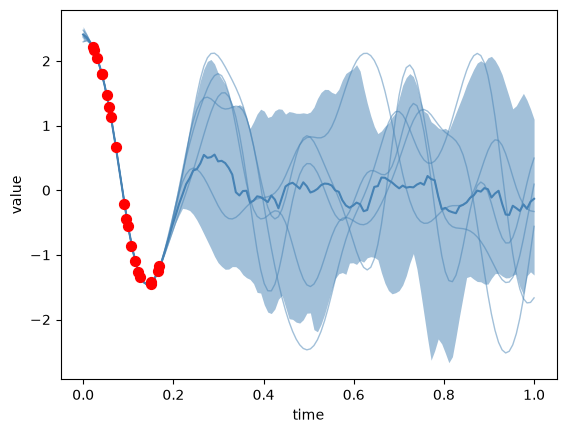

In [4]:
flow = GaussianProcessFlow(p0_kernel, p0_mean_fn, coords, device=device)
sampler = IntegratorSampler(flow=flow)
torch.manual_seed(1234)
samples_prior = sampler.sample(num_samples, num_steps=1_000)
plotter(samples_prior, num_samples=5)

## 5. Conditioning on the Pendulum ODE

`PendulumCondition` is an `EqualityCondition` with residual $r = \ddot\theta + \beta\dot\theta + \sin\theta$, computed by centred differences at the interior grid points. Its log-likelihood is $-\lVert r\rVert^2 / 2\sigma^2$, so $\sigma$ sets how tightly the ODE is enforced.

In [5]:
class PendulumCondition(EqualityCondition):
    """Damped pendulum ODE residual for a single-channel field on a uniform time grid."""

    def __init__(self, dt: float, sigma: float = 1.0, beta: float = 0.2):
        super().__init__(sigma=sigma)
        self.dt = float(dt)
        self.register_buffer("beta", torch.tensor(float(beta)))  # damping coefficient

    def residual(self, x: torch.Tensor) -> torch.Tensor:
        theta = x.squeeze(1)  # (B, N)
        # Centred differences at the interior points 1..N-2.
        dtheta_dt = (theta[:, 2:] - theta[:, :-2]) / (2 * self.dt)
        d2theta_dt2 = (theta[:, 2:] - 2 * theta[:, 1:-1] + theta[:, :-2]) / (self.dt * self.dt)
        residual = d2theta_dt2 + torch.sin(theta[:, 1:-1]) + self.beta * dtheta_dt
        return residual.unsqueeze(1)  # (B, 1, N-2)

  0%|          | 0/999 [00:00<?, ?it/s]

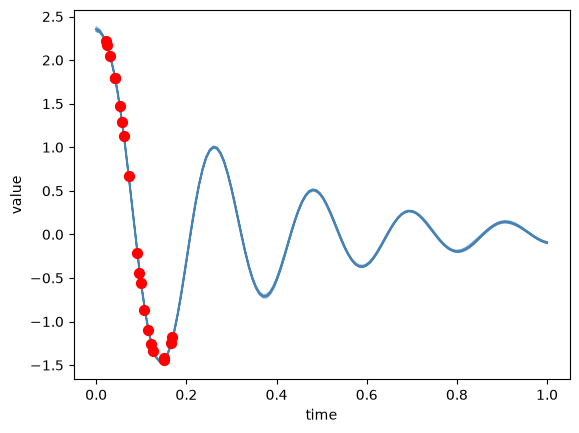

In [6]:
condition = PendulumCondition(dt, sigma=1e-2, beta=0.2).to(device)
guidance = GuidanceMC(flow, condition, num_mc_samples=100, max_norm=1e3).to(device)
samples = sampler.sample(num_samples, guidance=guidance, num_steps=1_000)
plotter(samples)